# Journal 4 - Compact variants on CPU

**Question.** Can the fine-tuned model run without a GPU, and what does that cost in quality?
**Answer.** D-q4 (4-bit, 1.9 GB) answers in ~6.4 s on a plain 8-vCPU CPU for about 20 euros a month on 36 000 tickets, against ~255 for a GPU endpoint. On val it keeps the quality: 0.3 silent errors per 100 tickets, no urgent ticket in a wrong desk. Smaller models were cancelled.

Pipeline on a Vertex CPU job (no GPU, no endpoint): merge the LoRA adapter into Qwen2.5-3B, convert to GGUF, quantise to `Q8_0` and `Q4_K_M`, predict the 293 val tickets one at a time. Job: 1 h 23 min, ~0.54 euro.

Vocabulary: **GGUF** is the single-file model format read by `llama.cpp` on CPU; **D-q8** keeps 8 bits per weight (`Q8_0`), **D-q4** about 4 bits (`Q4_K_M`). Same model, same answers in principle, smaller file and less RAM.

In [1]:
import json, sys
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path[:0] = [str(ROOT), str(ROOT / "notebooks")]
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import _viz as viz
import _tracking
viz.setup()

from src import scoring
from src.baselines import predict_majority, predict_rules, fit_tfidf, predict_tfidf

## 1. Quality on val: B2 vs D vs the two quantised models

In [2]:
R = ROOT / "docs/results"
val_x, val_y, _ = scoring.load_split(ROOT / "data/dataset/val.csv")
train_x, train_y, _ = scoring.load_split(ROOT / "data/dataset/train.csv")
def raw(system, filename):
    values = _tracking.load_predictions(ROOT, system, "val", R / filename, val_x)
    if values is None:
        raise FileNotFoundError(f"No tracked or local predictions for {system}/val")
    return values
b2_tracked = _tracking.load_predictions(ROOT, "B2", "val", None, val_x)
b2_raw = b2_tracked if b2_tracked is not None else predict_tfidf(fit_tfidf(train_x, train_y, 10.0), val_x)
val = {"B2": scoring.score(val_y, b2_raw),
       "D": scoring.score(val_y, raw("D", "d_qwen2.5-3b_full_run_val_predictions.csv")),
       "D-q8": scoring.score(val_y, raw("D-q8", "d_q8_full_run_val_predictions.csv")),
       "D-q4": scoring.score(val_y, raw("D-q4", "d_q4_full_run_val_predictions.csv"))}
SHOWN = ["silent_error_rate", "needless_triage_rate", "urgent_wrong_desk", "auto_routed_rate", "desk_accuracy",
         "exact_transaction_id", "exact_amount", "severity_score", "valid_json_rate"]
pd.DataFrame(val).loc[SHOWN].round(3)


[!] MLFLOW TRACKING NOTICE: Server unreachable at: http://127.0.0.1:5000
    (Connectivity check timed out in 0.1s to prevent notebook freeze)

    -> Local fallback active: reading predictions and metrics directly
       from local CSV files in `docs/results/`.

    INFO: To start the local MLflow server and enable live tracking:
       1. Open a separate terminal
       2. Run: mlflow server --host 127.0.0.1 --port 5000
          (or: uv run mlflow server --port 5000)



Using local historical prediction file: docs\results\d_qwen2.5-3b_full_run_val_predictions.csv
Using local historical prediction file: docs\results\d_q8_full_run_val_predictions.csv
Using local historical prediction file: docs\results\d_q4_full_run_val_predictions.csv


,B2,D,D-q8,D-q4
silent_error_rate,0.283,0.007,0.010,0.003
needless_triage_rate,0.007,0.007,0.007,0.010
urgent_wrong_desk,0.076,0.000,0.000,0.000
auto_routed_rate,0.863,0.833,0.829,0.826
desk_accuracy,0.949,0.986,0.990,0.986
exact_transaction_id,0.894,0.986,0.980,0.983
exact_amount,0.829,0.990,0.986,0.986
severity_score,1.478,0.027,0.051,0.020
valid_json_rate,1.000,0.990,0.990,0.986


Quantising to 8 or 4 bits loses nothing visible: 1 or 2 silent errors in 293 tickets for every D variant, still no urgent ticket in a wrong desk. The differences between D, D-q8 and D-q4 are a ticket or two and do not separate them: the test sets will.

## 2. What does it take to run? Speed, memory, monthly bill
Latency is measured on the 293 val tickets, one at a time (AMD EPYC 7B12, 8 vCPU). Monthly cost = mean latency x 36 000 tickets x CPU price per second (assumptions of `docs/scoring_protocol.md` section 6); the GPU figure is the 24/7 price of a T4 endpoint.

In [3]:
t = json.loads((R / "d_compact_full_run_timings.json").read_text(encoding="utf-8"))
TICKETS_PER_MONTH, CPU_EUR_PER_SECOND, GPU_ENDPOINT_EUR_PER_MONTH = 36_000, 0.00008, 255
ram_gb = {"D-q8": 3.8, "D-q4": 2.4}  # measured in production (docs/compact_variants.md)
infra = pd.DataFrame({
    "file (MB)": {"D-q8": t["q8"]["gguf_mb"], "D-q4": t["q4"]["gguf_mb"]},
    "RAM (GB)": ram_gb,
    "mean s / ticket": {"D-q8": t["q8"]["seconds_mean"], "D-q4": t["q4"]["seconds_mean"]},
    "p95 s / ticket": {"D-q8": t["q8"]["seconds_p95"], "D-q4": t["q4"]["seconds_p95"]},
})
infra["EUR / month"] = (infra["mean s / ticket"] * TICKETS_PER_MONTH * CPU_EUR_PER_SECOND).round(0)
infra.loc["D (T4 GPU)"] = [6200, 14, np.nan, np.nan, GPU_ENDPOINT_EUR_PER_MONTH]
infra

,file (MB),RAM (GB),mean s / ticket,p95 s / ticket,EUR / month
D-q8,3285,3.8,7.915,12.262,23.0
D-q4,1930,2.4,6.426,10.103,19.0
D (T4 GPU),6200,14.0,NaN,NaN,255.0


### Serving latency: mean and p95
Measured CPU timings are shown separately from the estimated monthly scenario.


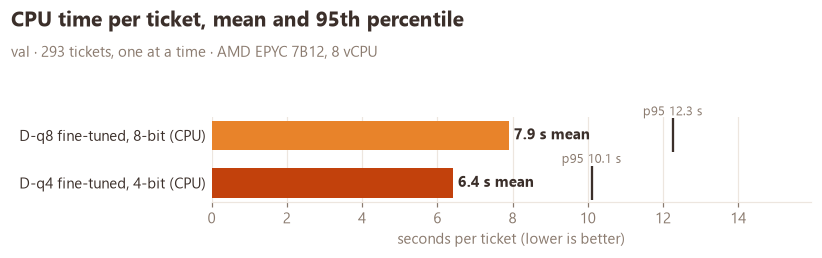

In [4]:
cpu = infra.loc[['D-q8', 'D-q4'], ['mean s / ticket', 'p95 s / ticket']]
fig, ax = plt.subplots(figsize=(7.5, 2.4))
viz.hbar(ax, [viz.LABELS[s] for s in cpu.index], cpu['mean s / ticket'].tolist(), [viz.SYSTEM_COLORS[s] for s in cpu.index], fmt='{:.1f} s mean')
ax.scatter(cpu['p95 s / ticket'], range(len(cpu)), marker='|', s=500, color=viz.INK, zorder=3)
for y, p in enumerate(cpu['p95 s / ticket']):
    ax.text(p, y - 0.42, f'p95 {p:.1f} s', ha='center', fontsize=8.5, color=viz.MUTED)
ax.set_xlim(0, cpu.values.max() * 1.3); ax.set_xlabel('seconds per ticket (lower is better)')
viz.headline(fig, 'CPU time per ticket, mean and 95th percentile', 'val · 293 tickets, one at a time · AMD EPYC 7B12, 8 vCPU')
viz.save(fig, '04_latency_mean_p95')
plt.show()

### File size and inference RAM


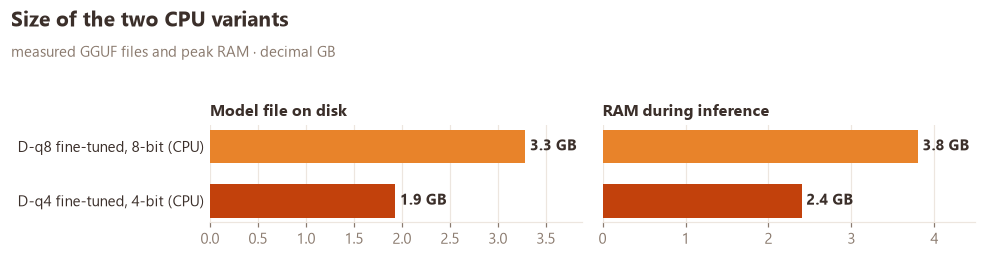

In [5]:
storage = infra.loc[['D-q8', 'D-q4'], ['file (MB)', 'RAM (GB)']]
fig, axes = plt.subplots(1, 2, figsize=(9, 2.4))
colors = [viz.SYSTEM_COLORS[s] for s in storage.index]
viz.hbar(axes[0], [viz.LABELS[s] for s in storage.index], (storage['file (MB)'] / 1000).tolist(), colors, fmt='{:.1f} GB')
viz.hbar(axes[1], [viz.LABELS[s] for s in storage.index], storage['RAM (GB)'].tolist(), colors, fmt='{:.1f} GB')
axes[1].set_yticklabels([])
axes[0].set_title('Model file on disk', loc='left', fontsize=10.5); axes[1].set_title('RAM during inference', loc='left', fontsize=10.5)
viz.headline(fig, 'Size of the two CPU variants', 'measured GGUF files and peak RAM · decimal GB')
viz.save(fig, '04_file_size_and_ram')
plt.show()

## 3. The choice: quality against monthly cost

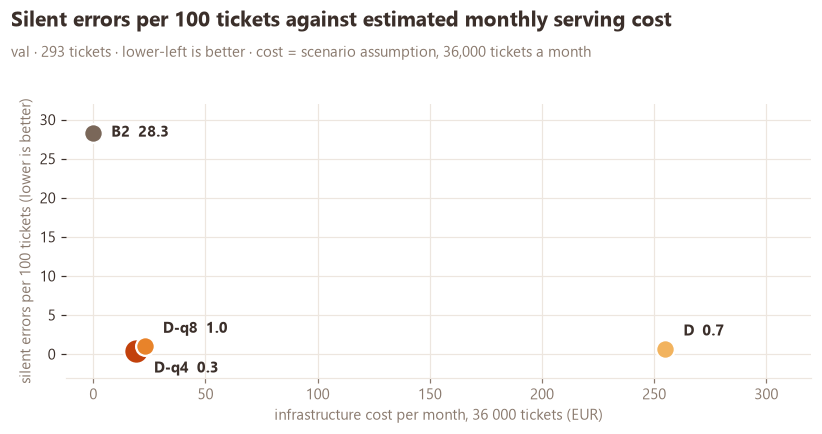

In [6]:
monthly = {"B2": 0, "D-q4": infra.loc["D-q4", "EUR / month"], "D-q8": infra.loc["D-q8", "EUR / month"], "D": GPU_ENDPOINT_EUR_PER_MONTH}
fig, ax = plt.subplots(figsize=(7.5, 4))
for k, x in monthly.items():
    y = 100 * val[k]["silent_error_rate"]
    ax.scatter(x, y, s=260 if k == "D-q4" else 150, color=viz.SYSTEM_COLORS[k], zorder=3, edgecolor="white", linewidth=1.5)
    dy = {"D-q4": -2.2, "D-q8": 2.2, "D": 2.2}.get(k, 0)
    ax.annotate(f"{k}  {y:.1f}", (x, y), (x + 8, y + dy), fontsize=10, fontweight="bold", va="center")
ax.set_xlim(-12, 320); ax.set_ylim(-3, 32); ax.set_yticks(range(0, 31, 5))
ax.set_xlabel("infrastructure cost per month, 36 000 tickets (EUR)"); ax.set_ylabel("silent errors per 100 tickets (lower is better)")
viz.headline(fig, "Silent errors per 100 tickets against estimated monthly serving cost", "val · 293 tickets · lower-left is better · cost = scenario assumption, 36,000 tickets a month")
viz.save(fig, "04_quality_vs_cost")
plt.show()

D-q4 sits in the best corner: as few silent errors as the GPU model at about 20 euros a month, 6.4 s per ticket (invisible in an asynchronous support workflow), 2.4 GB of RAM (smallest container tier). The price of caution is small: 1 ticket in 100 handed to a human without need.

## Decision (Gate G6): smaller models cancelled
Qwen2.5-1.5B and 0.5B could save at most ~9 euros a month more, cost another ~1.5 h of GPU, and have less capacity to extract exact ids, amounts and currencies, the source of silent errors. **D-q4 is locked as the candidate.**

The test sets are still unread. Next: single reading of `test_natural` and `test_traps`.